# Лабораторная работа №3. Семантический поиск

Цель: дообучить `intfloat/multilingual-e5-small` на парах «вопрос → релевантный отрывок» из SberQuAD и проверить, улучшилось ли ранжирование документов.

## Порядок работы

1. Загружаем подготовленные пары вопрос–документ.
2. Перед вопросом добавляем префикс `query:`, перед документом — `passage:`.
3. Измеряем качество базовой E5-модели.
4. Дообучаем модель с `MultipleNegativesRankingLoss`.
5. Сравниваем Recall@K, MRR, MAP и nDCG до и после обучения.

Для установки зависимостей выполните `%pip install -r requirements.txt`. Расширенная теория находится в `REPORT.md`.

## 1. Настройка путей и кэшей

In [1]:
from pathlib import Path
import os


def find_lab_root(lab_name: str) -> Path:
    current = Path.cwd().resolve()
    if current.name == lab_name:
        return current
    candidate = current / lab_name
    if candidate.exists():
        return candidate
    raise FileNotFoundError(
        f"Не найдена папка {lab_name}. Откройте ноутбук из корня проекта или из папки лабораторной."
    )


LAB_ROOT = find_lab_root("lab_3")
PROJECT_ROOT = LAB_ROOT.parent

# Кэши и временные файлы остаются на диске с проектом.
os.environ["HF_HOME"] = str(LAB_ROOT / ".cache" / "huggingface")
os.environ["HF_DATASETS_CACHE"] = str(LAB_ROOT / ".cache" / "huggingface" / "datasets")
os.environ["TRANSFORMERS_CACHE"] = str(LAB_ROOT / ".cache" / "huggingface" / "hub")
os.environ["TMP"] = str(LAB_ROOT / ".tmp")
os.environ["TEMP"] = str(LAB_ROOT / ".tmp")
os.environ["NLTK_DATA"] = str(LAB_ROOT / ".cache" / "nltk_data")

print(f"Папка лабораторной: {LAB_ROOT}")

Папка лабораторной: G:\ITMO\LLM_2026\lab_3


## 2. Подготовка обучающей и тестовой выборок

In [2]:

import pickle
import random
from dataclasses import dataclass
from pathlib import Path

from datasets import Dataset


@dataclass(frozen=True)
class SearchExample:
    query: str
    document: str
    label: float


def load_pickle_examples(path: Path) -> list[SearchExample]:
    with path.open("rb") as file:
        rows = pickle.load(file)
    return [SearchExample(query=row[0], document=row[1], label=float(row[2])) for row in rows]


def positive_examples(rows: list[SearchExample]) -> list[SearchExample]:
    return [row for row in rows if row.label == 1.0]


def build_training_dataset(
    rows: list[SearchExample],
    limit: int,
    seed: int,
) -> tuple[Dataset, dict[str, int]]:
    positives = positive_examples(rows)
    rng = random.Random(seed)
    rng.shuffle(positives)
    selected = positives[:limit]

    # E5 использует разные префиксы, чтобы отличать поисковый запрос
    # от документа даже при одинаковой структуре входного текста
    dataset = Dataset.from_dict(
        {
            "anchor": [f"query: {row.query}" for row in selected],
            "positive": [f"passage: {row.document}" for row in selected],
        }
    )
    metadata = {
        "all_rows": len(rows),
        "all_positive_rows": len(positives),
        "selected_positive_rows": len(selected),
        "seed": seed,
    }
    return dataset, metadata


def build_retrieval_test_set(
    rows: list[SearchExample],
    positive_limit: int,
) -> tuple[list[str], list[str], dict[str, int]]:
    """Оставляет по одному вопросу для каждого уникального документа.

    Из первых положительных примеров SberQuAD удаляются повторяющиеся контексты.
    Тогда у каждого вопроса есть ровно один известный релевантный документ,
    поэтому его позицию в ранжировании можно определить однозначно.
    """
    positives = positive_examples(rows)[:positive_limit]
    seen_documents: set[str] = set()
    queries: list[str] = []
    documents: list[str] = []

    for row in positives:
        if row.document in seen_documents:
            continue
        seen_documents.add(row.document)
        queries.append(row.query)
        documents.append(row.document)

    metadata = {
        "requested_positive_rows": positive_limit,
        "unique_queries": len(queries),
        "unique_documents": len(documents),
        "duplicates_removed": len(positives) - len(documents),
    }
    return queries, documents, metadata


def build_pairwise_test_set(
    rows: list[SearchExample],
    per_class_limit: int,
) -> tuple[list[str], list[str], list[int]]:
    positives = [row for row in rows if row.label == 1.0][:per_class_limit]
    negatives = [row for row in rows if row.label == 0.0][:per_class_limit]
    selected = positives + negatives
    return (
        [row.query for row in selected],
        [row.document for row in selected],
        [int(row.label) for row in selected],
    )

G:\ITMO\LLM_2026\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Метрики семантического поиска

In [3]:

from typing import Any

import numpy as np
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
from sentence_transformers import SentenceTransformer


def _encode(
    model: SentenceTransformer,
    texts: list[str],
    prefix: str,
    batch_size: int,
    description: str,
) -> np.ndarray:
    return model.encode(
        [f"{prefix}{text}" for text in texts],
        batch_size=batch_size,
        show_progress_bar=True,
        normalize_embeddings=True,
        convert_to_numpy=True,
    )


def evaluate_retrieval(
    model: SentenceTransformer,
    queries: list[str],
    documents: list[str],
    batch_size: int,
) -> tuple[dict[str, float | int], np.ndarray, np.ndarray]:
    query_embeddings = _encode(model, queries, "query: ", batch_size, "queries")
    document_embeddings = _encode(model, documents, "passage: ", batch_size, "documents")
    # Векторы нормализованы, поэтому скалярное произведение равно cosine similarity.
    # Получаем оценку каждой пары «вопрос — документ» одной матричной операцией.
    scores = query_embeddings @ document_embeddings.T

    top_k = min(10, len(documents))
    # argpartition быстро выбирает десять кандидатов без полной сортировки корпуса;
    # затем сортируем только их, чтобы получить точный порядок внутри top-10.
    candidate_ids = np.argpartition(-scores, kth=top_k - 1, axis=1)[:, :top_k]
    candidate_scores = np.take_along_axis(scores, candidate_ids, axis=1)
    order = np.argsort(-candidate_scores, axis=1)
    ranked_ids = np.take_along_axis(candidate_ids, order, axis=1)

    ranks = np.full(len(queries), np.inf, dtype=np.float64)
    for query_id, ids in enumerate(ranked_ids):
        positions = np.flatnonzero(ids == query_id)
        if positions.size:
            ranks[query_id] = float(positions[0] + 1)

    recall_at_5 = float(np.mean(ranks <= 5))
    recall_at_10 = float(np.mean(ranks <= 10))
    mrr_at_10 = float(np.mean(np.where(ranks <= 10, 1.0 / ranks, 0.0)))
    # Релевантный документ только один, поэтому AP@10 совпадает с reciprocal rank,
    # если этот документ находится в первой десятке.
    map_at_10 = mrr_at_10
    ndcg_at_10 = float(np.mean(np.where(ranks <= 10, 1.0 / np.log2(ranks + 1.0), 0.0)))

    metrics: dict[str, float | int] = {
        "queries": len(queries),
        "corpus_documents": len(documents),
        "accuracy_at_1": round(float(np.mean(ranks == 1)), 6),
        "recall_at_5": round(recall_at_5, 6),
        "recall_at_10": round(recall_at_10, 6),
        "mrr_at_10": round(mrr_at_10, 6),
        "map_at_10": round(map_at_10, 6),
        "ndcg_at_10": round(ndcg_at_10, 6),
    }
    return metrics, ranks, ranked_ids


def evaluate_pairwise(
    model: SentenceTransformer,
    queries: list[str],
    documents: list[str],
    labels: list[int],
    batch_size: int,
) -> dict[str, Any]:
    query_embeddings = _encode(model, queries, "query: ", batch_size, "pair queries")
    document_embeddings = _encode(model, documents, "passage: ", batch_size, "pair documents")
    similarities = np.sum(query_embeddings * document_embeddings, axis=1)
    labels_array = np.asarray(labels)
    positive_scores = similarities[labels_array == 1]
    negative_scores = similarities[labels_array == 0]
    correlation = spearmanr(labels_array, similarities).statistic

    return {
        "pairs": len(labels),
        "roc_auc": round(float(roc_auc_score(labels_array, similarities)), 6),
        "spearman": round(float(correlation), 6),
        "positive_cosine_mean": round(float(np.mean(positive_scores)), 6),
        "negative_cosine_mean": round(float(np.mean(negative_scores)), 6),
        "cosine_margin": round(float(np.mean(positive_scores) - np.mean(negative_scores)), 6),
    }


def ranking_examples(
    queries: list[str],
    documents: list[str],
    baseline_ranks: np.ndarray,
    baseline_ids: np.ndarray,
    fine_tuned_ranks: np.ndarray,
    fine_tuned_ids: np.ndarray,
    count_each: int = 5,
) -> list[dict[str, Any]]:
    # Ранг inf означает, что документ не попал в top-10; для сравнения считаем
    # его условной позицией 11, следующей сразу после наблюдаемой выдачи.
    baseline_numeric = np.where(np.isfinite(baseline_ranks), baseline_ranks, 11.0)
    fine_tuned_numeric = np.where(np.isfinite(fine_tuned_ranks), fine_tuned_ranks, 11.0)
    improvement = baseline_numeric - fine_tuned_numeric
    improved_ids = np.argsort(-improvement)[:count_each]
    degraded_ids = np.argsort(improvement)[:count_each]

    rows: list[dict[str, Any]] = []
    for change_type, selected_ids in [("improved", improved_ids), ("degraded", degraded_ids)]:
        for query_id in selected_ids:
            rows.append(
                {
                    "change": change_type,
                    "query": queries[query_id],
                    "relevant_document": documents[query_id],
                    "baseline_rank": int(baseline_ranks[query_id]) if np.isfinite(baseline_ranks[query_id]) else ">10",
                    "fine_tuned_rank": int(fine_tuned_ranks[query_id]) if np.isfinite(fine_tuned_ranks[query_id]) else ">10",
                    "baseline_top1": documents[int(baseline_ids[query_id, 0])],
                    "fine_tuned_top1": documents[int(fine_tuned_ids[query_id, 0])],
                }
            )
    return rows

## 4. Базовая оценка, дообучение и повторная оценка

In [4]:

import argparse
import json
import os
import random
from pathlib import Path
from time import perf_counter
from typing import Any

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sentence_transformers import (
    SentenceTransformer,
    SentenceTransformerTrainer,
    SentenceTransformerTrainingArguments,
)
from sentence_transformers.sentence_transformer.losses import MultipleNegativesRankingLoss
from sentence_transformers.sentence_transformer.training_args import BatchSamplers



MODEL_NAME = "intfloat/multilingual-e5-small"
LAB_ROOT = LAB_ROOT
PROJECT_ROOT = LAB_ROOT.parent
DEFAULT_DATA_DIR = PROJECT_ROOT / "labs_data" / "lab3(base)" / "lab3"


def parse_args() -> argparse.Namespace:
    parser = argparse.ArgumentParser(description="Лабораторная №3: дообучение multilingual E5 для поиска")
    parser.add_argument("--data-dir", type=Path, default=DEFAULT_DATA_DIR)
    parser.add_argument("--output-dir", type=Path, default=LAB_ROOT / "artifacts")
    parser.add_argument("--train-limit", type=int, default=12000)
    parser.add_argument("--test-positive-limit", type=int, default=1000)
    parser.add_argument("--pairwise-per-class", type=int, default=1000)
    parser.add_argument("--epochs", type=float, default=1.0)
    parser.add_argument("--batch-size", type=int, default=16)
    parser.add_argument("--encode-batch-size", type=int, default=64)
    parser.add_argument("--learning-rate", type=float, default=2e-5)
    parser.add_argument("--max-seq-length", type=int, default=256)
    parser.add_argument("--temperature", type=float, default=0.01)
    parser.add_argument("--seed", type=int, default=42)
    return parser.parse_args()


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def load_model(device: str, max_seq_length: int) -> SentenceTransformer:
    model = SentenceTransformer(MODEL_NAME, device=device)
    model.max_seq_length = max_seq_length
    return model


def train_model(
    model: SentenceTransformer,
    dataset: Any,
    args: argparse.Namespace,
) -> tuple[dict[str, Any], list[dict[str, Any]]]:
    checkpoint_dir = args.output_dir / "checkpoint"
    trainer_output = args.output_dir / "trainer"
    use_bfloat16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()

    training_args = SentenceTransformerTrainingArguments(
        output_dir=str(trainer_output),
        num_train_epochs=args.epochs,
        per_device_train_batch_size=args.batch_size,
        learning_rate=args.learning_rate,
        # В Transformers v5 дробное warmup_steps трактуется как доля всех шагов:
        # 0.1 означает линейный разогрев learning rate на первых 10% обучения.
        warmup_steps=0.1,
        bf16=use_bfloat16,
        fp16=torch.cuda.is_available() and not use_bfloat16,
        batch_sampler=BatchSamplers.NO_DUPLICATES,
        save_strategy="no",
        eval_strategy="no",
        logging_strategy="steps",
        logging_steps=50,
        logging_first_step=True,
        report_to="none",
        run_name="lab-3-multilingual-e5-sberquad",
        seed=args.seed,
        data_seed=args.seed,
        dataloader_num_workers=0,
    )
    # Остальные документы текущего batch становятся отрицательными примерами.
    # Это даёт много сравнений без хранения отдельных негативных пар в датасете.
    loss = MultipleNegativesRankingLoss(model, scale=1.0 / args.temperature)
    trainer = SentenceTransformerTrainer(
        model=model,
        args=training_args,
        train_dataset=dataset,
        loss=loss,
    )

    started = perf_counter()
    train_result = trainer.train()
    seconds = round(perf_counter() - started, 2)
    model.save_pretrained(str(checkpoint_dir))

    summary = {
        "seconds": seconds,
        "train_runtime": round(float(train_result.metrics.get("train_runtime", seconds)), 4),
        "train_loss": round(float(train_result.metrics.get("train_loss", 0.0)), 6),
        "steps": int(train_result.metrics.get("global_step", trainer.state.global_step)),
    }
    return summary, trainer.state.log_history


def create_metric_plot(results: dict[str, Any], output_dir: Path) -> None:
    metric_keys = ["recall_at_5", "mrr_at_10", "map_at_10", "ndcg_at_10"]
    labels = ["Recall@5", "MRR@10", "MAP@10", "nDCG@10"]
    baseline = [results["baseline"]["retrieval"][key] for key in metric_keys]
    fine_tuned = [results["fine_tuned"]["retrieval"][key] for key in metric_keys]
    x = np.arange(len(labels))
    width = 0.36

    fig, axis = plt.subplots(figsize=(9, 5))
    axis.bar(x - width / 2, baseline, width, label="Baseline", color="#9aa6b2")
    axis.bar(x + width / 2, fine_tuned, width, label="Fine-tuned", color="#377eb8")
    axis.set_xticks(x, labels)
    axis.set_ylim(0, 1)
    axis.set_ylabel("Значение метрики")
    axis.set_title("SberQuAD: точный поиск по 906 документам")
    axis.grid(axis="y", alpha=0.25)
    axis.legend()
    for container in axis.containers:
        axis.bar_label(container, fmt="%.3f", padding=3, fontsize=8)
    fig.tight_layout()
    fig.savefig(output_dir / "retrieval_metrics.png", dpi=180, bbox_inches="tight")
    plt.close(fig)


def create_training_plot(history: list[dict[str, Any]], output_dir: Path) -> None:
    points = [(entry["step"], entry["loss"]) for entry in history if "loss" in entry and "step" in entry]
    if not points:
        return
    fig, axis = plt.subplots(figsize=(8, 4.5))
    axis.plot([point[0] for point in points], [point[1] for point in points], marker="o", markersize=3)
    axis.set_xlabel("Шаг обучения")
    axis.set_ylabel("MultipleNegativesRankingLoss")
    axis.set_title("Динамика contrastive loss")
    axis.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(output_dir / "training_loss.png", dpi=180, bbox_inches="tight")
    plt.close(fig)


def run_experiment(args: argparse.Namespace) -> None:
    """Запускает оценку, дообучение и повторную оценку модели."""

    set_seed(args.seed)
    args.output_dir.mkdir(parents=True, exist_ok=True)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"Device: {device}", flush=True)
    if device == "cuda":
        print(f"GPU: {torch.cuda.get_device_name(0)}", flush=True)

    train_rows = load_pickle_examples(args.data_dir / "trainval.pkl")
    test_rows = load_pickle_examples(args.data_dir / "test.pkl")
    train_dataset, train_metadata = build_training_dataset(train_rows, args.train_limit, args.seed)
    retrieval_queries, retrieval_documents, retrieval_metadata = build_retrieval_test_set(
        test_rows, args.test_positive_limit
    )
    pair_queries, pair_documents, pair_labels = build_pairwise_test_set(test_rows, args.pairwise_per_class)

    model = load_model(device, args.max_seq_length)
    parameter_count = sum(parameter.numel() for parameter in model.parameters())

    print("\n=== Baseline evaluation ===", flush=True)
    baseline_retrieval, baseline_ranks, baseline_ids = evaluate_retrieval(
        model, retrieval_queries, retrieval_documents, args.encode_batch_size
    )
    baseline_pairwise = evaluate_pairwise(
        model, pair_queries, pair_documents, pair_labels, args.encode_batch_size
    )
    print(f"Baseline retrieval: {baseline_retrieval}", flush=True)
    print(f"Baseline pairwise: {baseline_pairwise}", flush=True)

    print("\n=== Fine-tuning ===", flush=True)
    training, history = train_model(model, train_dataset, args)

    print("\n=== Fine-tuned evaluation ===", flush=True)
    fine_tuned_retrieval, fine_tuned_ranks, fine_tuned_ids = evaluate_retrieval(
        model, retrieval_queries, retrieval_documents, args.encode_batch_size
    )
    fine_tuned_pairwise = evaluate_pairwise(
        model, pair_queries, pair_documents, pair_labels, args.encode_batch_size
    )
    print(f"Fine-tuned retrieval: {fine_tuned_retrieval}", flush=True)
    print(f"Fine-tuned pairwise: {fine_tuned_pairwise}", flush=True)

    retrieval_delta = {
        key: round(float(fine_tuned_retrieval[key]) - float(baseline_retrieval[key]), 6)
        for key in ["accuracy_at_1", "recall_at_5", "recall_at_10", "mrr_at_10", "map_at_10", "ndcg_at_10"]
    }
    pairwise_delta = {
        key: round(float(fine_tuned_pairwise[key]) - float(baseline_pairwise[key]), 6)
        for key in ["roc_auc", "spearman", "positive_cosine_mean", "negative_cosine_mean", "cosine_margin"]
    }

    results: dict[str, Any] = {
        "experiment": {
            "model": MODEL_NAME,
            "parameters": parameter_count,
            "device": device,
            "gpu": torch.cuda.get_device_name(0) if device == "cuda" else None,
            "torch": torch.__version__,
            "sentence_transformers": __import__("sentence_transformers").__version__,
            "seed": args.seed,
            "epochs": args.epochs,
            "batch_size": args.batch_size,
            "learning_rate": args.learning_rate,
            "temperature": args.temperature,
            "max_seq_length": args.max_seq_length,
            "query_prefix": "query: ",
            "passage_prefix": "passage: ",
            "loss": "MultipleNegativesRankingLoss с негативами внутри batch",
            "mixed_precision": "bfloat16" if device == "cuda" and torch.cuda.is_bf16_supported() else "float16" if device == "cuda" else "float32",
        },
        "data": {
            "source": "Подготовленные pickle-файлы SberQuAD из материалов лабораторной",
            "train": train_metadata,
            "retrieval_test": retrieval_metadata,
            "pairwise_test_pairs": len(pair_labels),
        },
        "baseline": {"retrieval": baseline_retrieval, "pairwise": baseline_pairwise},
        "fine_tuned": {"retrieval": fine_tuned_retrieval, "pairwise": fine_tuned_pairwise},
        "delta": {"retrieval": retrieval_delta, "pairwise": pairwise_delta},
        "training": training,
        "training_history": history,
    }

    examples = ranking_examples(
        retrieval_queries,
        retrieval_documents,
        baseline_ranks,
        baseline_ids,
        fine_tuned_ranks,
        fine_tuned_ids,
    )
    pd.DataFrame(examples).to_csv(args.output_dir / "ranking_changes.csv", index=False, encoding="utf-8-sig")
    with (args.output_dir / "results.json").open("w", encoding="utf-8") as file:
        json.dump(results, file, ensure_ascii=False, indent=2)
    create_metric_plot(results, args.output_dir)
    create_training_plot(history, args.output_dir)
    print(f"\nГотово. Результаты: {args.output_dir / 'results.json'}", flush=True)


def main() -> None:
    run_experiment(parse_args())

## 5. Запуск эксперимента

Полный запуск сначала оценивает исходную модель, затем обучает её и повторяет оценку. Чтобы пересчитать эксперимент, установите `RUN_TRAINING = True`.

In [5]:
EXPERIMENT_ARGS = argparse.Namespace(
    data_dir=PROJECT_ROOT / "labs_data" / "lab3(base)" / "lab3",
    output_dir=LAB_ROOT / "artifacts",
    train_limit=12_000,
    test_positive_limit=1_000,
    pairwise_per_class=1_000,
    epochs=1.0,
    batch_size=16,
    encode_batch_size=64,
    learning_rate=2e-5,
    max_seq_length=256,
    temperature=0.01,
    seed=42,
)

RUN_TRAINING = False

if RUN_TRAINING:
    run_experiment(EXPERIMENT_ARGS)
else:
    print("Обучение пропущено. Ниже загружаются сохранённые результаты.")

Обучение пропущено. Ниже загружаются сохранённые результаты.


## 6. Полученные результаты

,metric,baseline,fine_tuned,delta
0,accuracy_at_1,0.908389,0.923841,0.015452
1,recall_at_5,0.971302,0.980132,0.008830
2,recall_at_10,0.977925,0.990066,0.012141
3,mrr_at_10,0.935134,0.948844,0.013710
4,map_at_10,0.935134,0.948844,0.013710
5,ndcg_at_10,0.945749,0.959014,0.013265


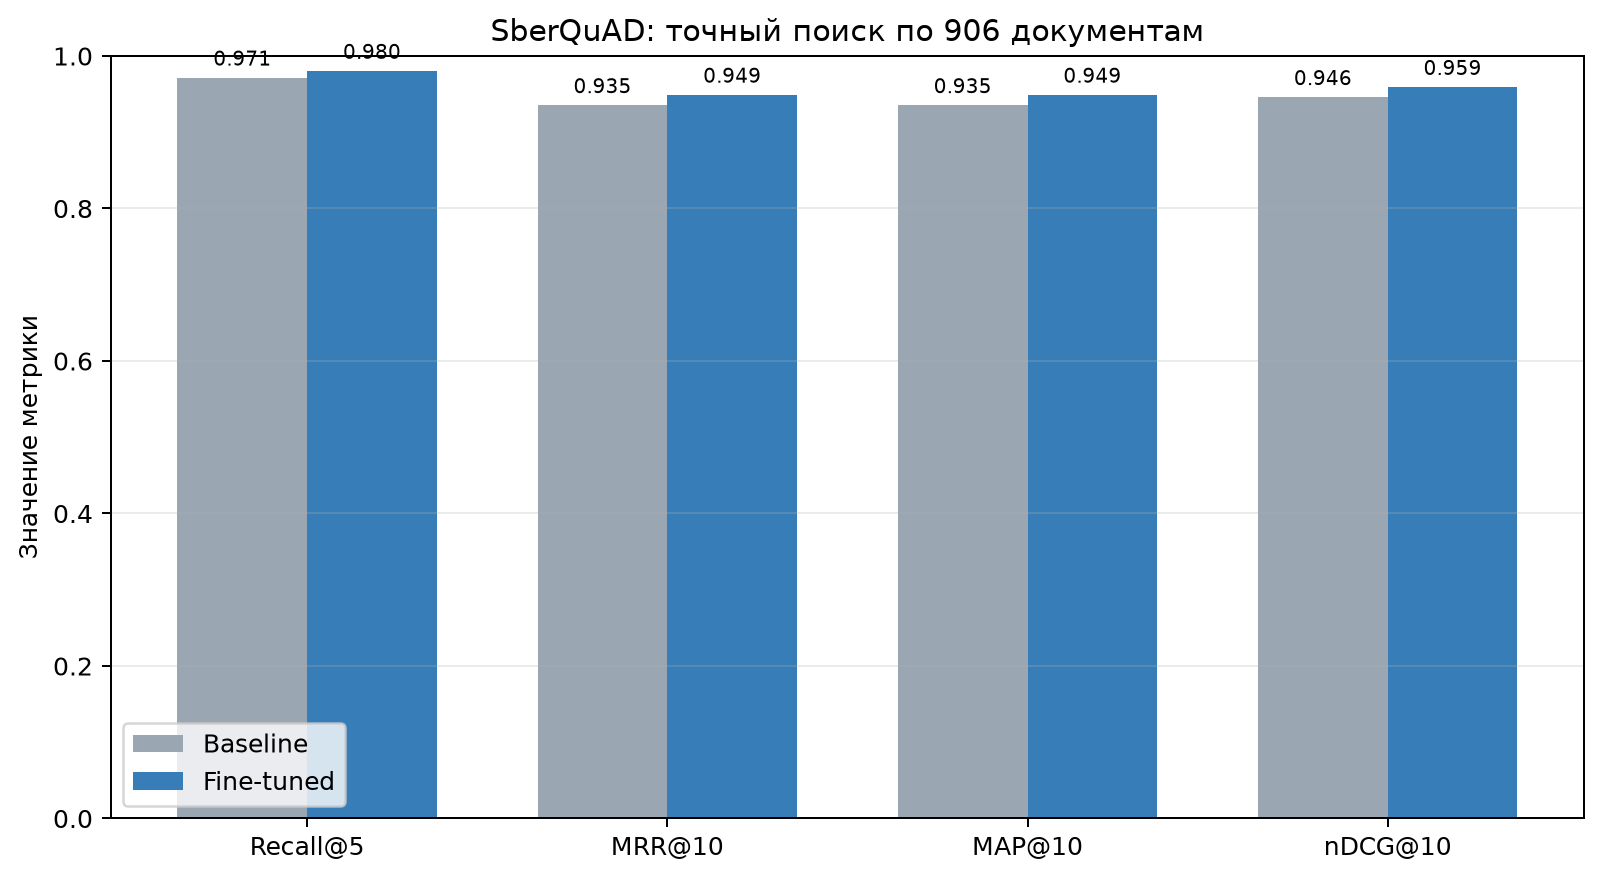

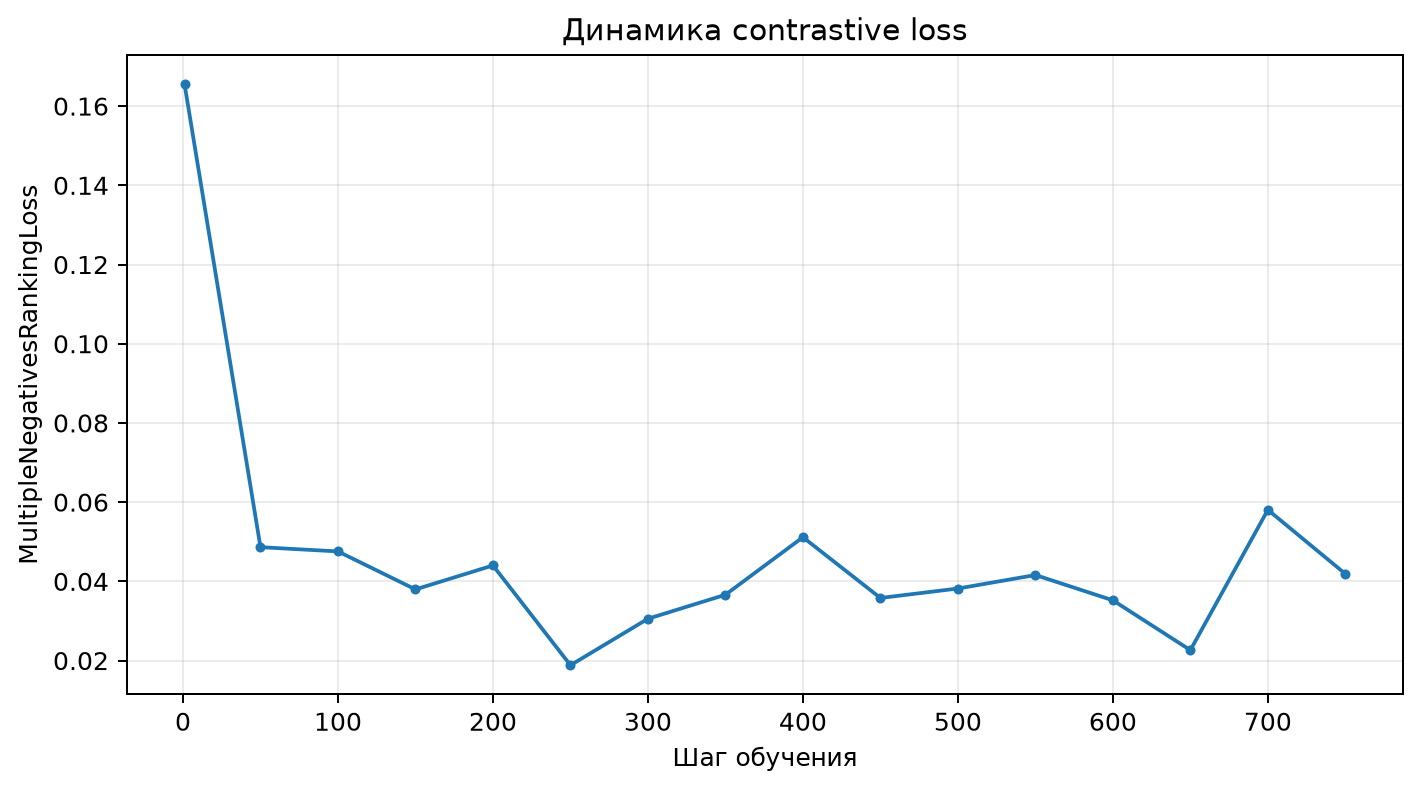

In [6]:
from IPython.display import Image, display

results_path = LAB_ROOT / "artifacts" / "results.json"
results = json.loads(results_path.read_text(encoding="utf-8"))

metrics = ["accuracy_at_1", "recall_at_5", "recall_at_10", "mrr_at_10", "map_at_10", "ndcg_at_10"]
rows = []
for metric in metrics:
    rows.append({
        "metric": metric,
        "baseline": results["baseline"]["retrieval"][metric],
        "fine_tuned": results["fine_tuned"]["retrieval"][metric],
        "delta": results["delta"]["retrieval"][metric],
    })

display(pd.DataFrame(rows))
display(Image(filename=str(LAB_ROOT / "artifacts" / "retrieval_metrics.png")))
display(Image(filename=str(LAB_ROOT / "artifacts" / "training_loss.png")))

## Вывод

После дообучения релевантные документы в среднем поднимаются выше в выдаче. Рост Recall@K означает, что нужный документ чаще попадает в первые K результатов; рост MRR и nDCG показывает улучшение его позиции внутри верхней части выдачи.